## Plot Abil Output

In [1]:
import cartopy.crs as ccrs
import cartopy as cart
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from yaml import load, Loader
from datetime import datetime


In [2]:
def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start).resolve()
    for path in [start, *start.parents]:
        if (path / "environment.yml").exists():
            return path
    raise FileNotFoundError("Could not find project root containing environment.yml")


PROJECT_ROOT = find_project_root()
CONFIG_PATH = PROJECT_ROOT / "2-phase example" / "2-phase.yml"

with CONFIG_PATH.open('r') as f:
    model_config = load(f, Loader=Loader)

run_name = 'pro_na'
current_date = datetime.today().strftime('%Y-%m-%d')
file = current_date + '_mean_abundance'
post_dir = PROJECT_ROOT / model_config['path_out'] / run_name / 'posts'
ds = xr.open_dataset(post_dir / f"{file}.nc")


In [3]:
print(ds)

<xarray.Dataset>
Dimensions:          (time: 12, depth: 1, lat: 36, lon: 61)
Coordinates:
  * time             (time) int64 1 2 3 4 5 6 7 8 9 10 11 12
  * depth            (depth) int64 0
  * lat              (lat) int64 35 36 37 38 39 40 41 ... 64 65 66 67 68 69 70
  * lon              (lon) int64 -60 -59 -58 -57 -56 -55 ... -5 -4 -3 -2 -1 0
Data variables:
    Prochlorococcus  (time, depth, lat, lon) float64 ...
Attributes:
    Conventions:  CF-1.5


### Create of map of surface Prochlorococcus abundance in April

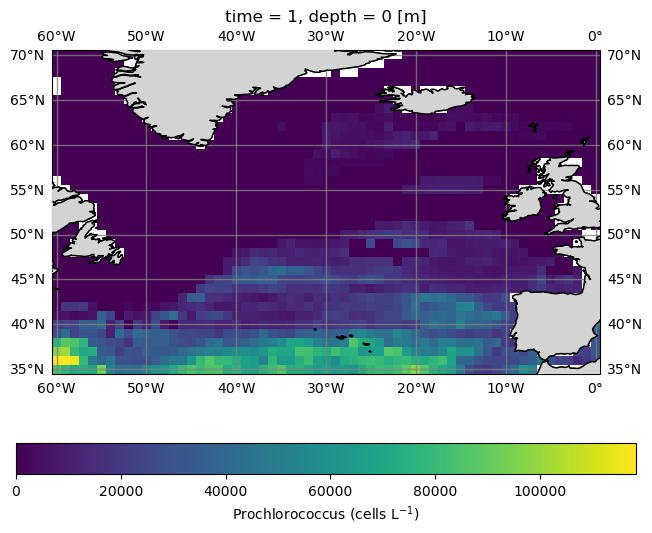

In [4]:
fig = plt.figure(figsize=(8, 6))
ax = plt.axes(projection=ccrs.PlateCarree())

# Add coastlines and land fill color
ax.coastlines()
ax.add_feature(cart.feature.LAND, 
               linewidth = 1, 
               zorder=3, 
               edgecolor='k', 
               facecolor="lightgray")

ax.gridlines(draw_labels=True, 
             linewidth=1,
             color='gray',
             alpha=0.8,
             linestyle='-',
             zorder=1
)
p = ds['Prochlorococcus'].sel(
    depth=0, 
    time=1
    ).plot(
        x='lon',
        y='lat',
        transform=ccrs.PlateCarree(),
        add_colorbar=False,)


cbar = plt.colorbar(p, 
                    location='bottom', 
                    label="Prochlorococcus (cells L$^{-1}$)")